# Очистка от структурных выбросов и минимальный объём обучающей выборки

Дополнительный ноутбук к работе по проверке методов NNF и NNFA (курс "Нейросети", НИУ ВШЭ Пермь).

Авторы методов NNF и NNFA назвали направление дальнейших исследований: "необходимо экспериментально показать,
что очистка датасетов от выбросов методами NNF и NNFA снижает требования к минимально допустимому объёму
обучающих выборок". В предварительном эксперименте (`Код_и_результаты/src/exp4_sample_size.py`) это проверено на одном наборе данных, при 5 и 10 % выбросов
и в основном при известном числе выбросов. Здесь проверка расширена, чтобы вывод не держался на этих условиях:

* три набора данных: Concrete Compressive Strength, California Housing и модельная функция Фридмана;
* загрязнение 0 % (контроль), 5, 10 и 20 %;
* очистка и при известном числе выбросов, как в препринте, и без него;
* выигрыш в объёме данных оценивается не для одной целевой точности, а по всему диапазону объёмов.

Ноутбук самостоятельный: весь код находится в его ячейках, рядом нужна только папка `data` с файлами наборов.

## 1. Постановка

**Цель.** Проверить, позволяет ли очистка обучающей выборки методом NNFA получить нейросетевую модель той же
точности по меньшему числу наблюдений, и оценить, во сколько раз меньше данных для этого нужно.

Идея проверки простая. Если выбросы мешают модели, то для заданной точности загрязнённой выборке нужно больше
наблюдений, чем очищенной. Поэтому одна и та же итоговая модель обучается на выборках разного объёма *Q*,
загрязнённых и очищенных, и сравниваются кривые "ошибка на тесте в зависимости от *Q*". Сдвиг между кривыми
по горизонтали и показывает, сколько данных экономит очистка.

| Решение | Обоснование |
|---|---|
| Три набора: Concrete (1030 наблюдений, 8 входов), California Housing (20 433 наблюдения, 8 входов), функция Фридмана № 1 (10 входов, из них 5 значимых, шум σ = 1) | Два реальных набора, на которых проверялись методы в препринте, и модельный набор, где закономерность известна точно и собственных аномалий нет |
| Выбросы структурные: *y* сдвигается на 2σ<sub>y</sub> к центру распределения и остаётся внутри диапазона *y* | Тот же тип выбросов, что в основной работе. При мощности 2σ методы надёжно их находят (раздел 4 ноутбука `Итоговый_ноутбук.ipynb`), поэтому проверяется польза очистки, а не предел чувствительности |
| Загрязнение 0, 5, 10 и 20 % | 0 % проверяет, не вредит ли очистка чистым данным; 20 % показывает, как меняется эффект при сильном загрязнении |
| Объёмы обучающей выборки: Concrete *Q* = 100…824 (7 значений), California и Фридман *Q* = 150…1500 (6 значений), с примерно постоянным шагом в логарифмической шкале | Для Concrete верхняя граница равна размеру набора за вычетом теста. Для больших наборов она ограничена временем расчёта |
| Выборки разного объёма вложены: меньшая является началом большей | Соседние значения *Q* различаются только добавленными наблюдениями, это уменьшает разброс кривых |
| Тестовая часть без выбросов: 206 наблюдений для Concrete, 2000 для двух других наборов | Ошибка на тесте должна измерять качество модели, а не наличие выбросов в тесте |
| Стратегии подготовки данных: без очистки; NNFA при известном числе выбросов *m*; NNFA с порогом λ(*n*) за один шаг; последовательное удаление; идеальная очистка | Первая и последняя задают нижнюю и верхнюю границы эффекта. NNFA при известном *m* соответствует протоколу препринта. Порог λ(*n*) и последовательное удаление не требуют знать *m*, то есть применимы на практике |
| Последовательное удаление считается только для Concrete | После каждого удаления ансамбль обучается заново. При *Q* = 1500 и 20 % выбросов это более 300 обучений ансамбля на одну выборку, что для двух больших наборов не помещается в разумное время расчёта |
| NNFA: ξ = 0,1, интервал АКХН в варианте кода авторов, Adam, 500 эпох | Как в основной работе |
| Итоговая модель: персептрон (32, 16) из scikit-learn со строгим критерием останова; RMSE на тесте усредняется по двум начальным инициализациям | Как в разделе 6 итогового ноутбука и в предварительном эксперименте. Итоговая модель отличается от сетей NNFA: это модель, которую строил бы аналитик, и ради её точности делается очистка |
| 12 повторов: новое разбиение на обучение и тест, новые позиции выбросов, новые начальные веса | Позволяет построить доверительные интервалы и парные сравнения; при этом весь расчёт занимает несколько часов |

### Как измеряется выигрыш в объёме данных

Для каждой стратегии строится средняя по повторам кривая RMSE(*Q*). Используются две меры.

1. **Кратность снижения при полном объёме.** Цель — точность, которую без очистки даёт вся обучающая выборка
   (*Q*<sub>max</sub>). Для стратегии находится наименьший объём *q*<sub>min</sub>, при котором её средний RMSE
   не хуже цели. Между узлами сетки используется линейная интерполяция по log *Q*. Кратность снижения равна
   *Q*<sub>max</sub> / *q*<sub>min</sub>. Это та же мера, что в предварительном эксперименте.
2. **Кратность снижения по всему диапазону.** Та же процедура повторяется для каждого объёма *Q*<sub>0</sub> сетки:
   цель — RMSE без очистки при *Q*<sub>0</sub>, и находится объём, при котором очищенная выборка даёт ту же
   точность. Отношение *Q*<sub>0</sub> к этому объёму показывает выигрыш при разных размерах выборки. Если
   очищенная выборка уже при наименьшем *Q* сетки точнее цели, точное значение не определяется, и выигрыш
   указывается как нижняя граница.

Доверительные интервалы кратности строятся бутстрепом по повторам. Значимость различий проверяется парным
критерием Уилкоксона по всем парам (*Q*, повтор) с поправкой Холма.

In [1]:
# Параметры расчёта.
# RECOMPUTE = False: сохранённые результаты (results/experiment.csv) загружаются, если они есть;
#                    если их нет, недостающие расчёты выполняются и сохраняются.
# RECOMPUTE = True:  все расчёты выполняются заново (около 3,5 ч на двух ядрах процессора).
RECOMPUTE = False
N_JOBS = -1          # число параллельных процессов; -1 означает все ядра

import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import math, shutil, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import norm, wilcoxon
from sklearn.datasets import make_friedman1
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

HERE = Path.cwd()
DATA, RES, FIG = HERE / "data", HERE / "results", HERE / "figures"
RES.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SMOKE = os.environ.get("LR6_SMOKE") == "1"       # служебный быстрый прогон для проверки кода
CONTAMINATIONS = [0.0, 0.05, 0.10, 0.20]
N_RUNS = 12
K_SIGMA = 2.0
XI = 0.1
MLP_INITS = 2
SIZES = {"Concrete": [100, 140, 200, 280, 400, 570, 824],
         "California": [150, 250, 400, 650, 1000, 1500],
         "Friedman": [150, 250, 400, 650, 1000, 1500]}
N_TEST = {"Concrete": 206, "California": 2000, "Friedman": 2000}
if SMOKE:
    CONTAMINATIONS, N_RUNS = [0.0, 0.10], 1
    SIZES = {"Concrete": [100, 200], "California": [150, 250], "Friedman": [150, 250]}
print("загрязнение:", CONTAMINATIONS, "| повторов:", N_RUNS, "| процессов:", N_JOBS)

загрязнение: [0.0, 0.05, 0.1, 0.2] | повторов: 12 | процессов: -1


## 2. Данные

* **Concrete Compressive Strength**: прочность бетона (МПа) по составу смеси и возрасту, 1030 наблюдений,
  8 входов. Основной набор препринта и основной работы.
* **California Housing**: медианная стоимость жилья в районе (в сотнях тысяч долларов) по 8 признакам района.
  Признаки построены так же, как в `sklearn.datasets.fetch_california_housing`: средний доход, средний возраст
  домов, среднее число комнат и спален на домохозяйство, население, средняя заполненность, широта и долгота.
  Файл взят из открытого репозитория книги А. Жерона (`housing.csv`); 207 строк без числа спален удалены.
  Стоимость в исходных данных ограничена сверху значением 5,0 (около 5 % районов), это свойство самих данных.
  Четыре признака (комнаты, спальни, население, заполненность) имеют очень длинные хвосты: например, средняя
  заполненность доходит до 1243 человек на домохозяйство. Поэтому они логарифмируются, а все признаки
  обрезаются по 0,5 %- и 99,5 %-квантилям. Без этого отдельные районы теста с крайними значениями признаков
  давали итоговой модели ошибку в несколько раз больше разброса *y*, и результат определялся этими
  районами, а не очисткой. Целевая переменная не меняется, так что структурные выбросы вносятся так же.
* **Функция Фридмана № 1**: *y* = 10 sin(π*x*<sub>1</sub>*x*<sub>2</sub>) + 20(*x*<sub>3</sub> − 0,5)² + 10*x*<sub>4</sub> +
  5*x*<sub>5</sub> + ε, где *x*<sub>1</sub>…*x*<sub>10</sub> равномерно распределены на [0; 1], а ε ~ N(0; 1).
  Входы *x*<sub>6</sub>…*x*<sub>10</sub> на *y* не влияют. Данные генерируются заново в каждом повторе.

In [2]:
def load_concrete():
    path = DATA / "concrete.csv"
    if not path.exists():                          # запасной путь: папка основного проекта
        alt = HERE.parent / "Код_и_результаты" / "data" / "concrete.csv"
        DATA.mkdir(exist_ok=True); shutil.copy(alt, path)
    d = pd.read_csv(path)
    return d.iloc[:, :8].to_numpy(float), d["strength"].to_numpy(float)


def load_california():
    path = DATA / "housing.csv"
    if not path.exists():
        import urllib.request
        DATA.mkdir(exist_ok=True)
        urllib.request.urlretrieve(
            "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv", path)
    d = pd.read_csv(path).dropna(subset=["total_bedrooms"])
    hh = d["households"]
    X = np.column_stack([d["median_income"], d["housing_median_age"], d["total_rooms"] / hh,
                         d["total_bedrooms"] / hh, d["population"], d["population"] / hh,
                         d["latitude"], d["longitude"]])
    X = X.astype(float)
    X[:, 2:6] = np.log(X[:, 2:6])                  # комнаты, спальни, население, заполненность
    X = np.clip(X, np.percentile(X, 0.5, axis=0), np.percentile(X, 99.5, axis=0))
    return X, (d["median_house_value"] / 1e5).to_numpy(float)


CONCRETE, CALIFORNIA = load_concrete(), load_california()


def split(ds, run):
    """Тестовая часть и пул обучающих наблюдений для повтора run.
    Обучающая выборка объёма Q — первые Q наблюдений пула (выборки вложены)."""
    rng = np.random.default_rng([{"Concrete": 1, "California": 2, "Friedman": 3}[ds], run])
    if ds == "Friedman":
        n = N_TEST[ds] + max(SIZES[ds])
        X, y = make_friedman1(n_samples=n, n_features=10, noise=1.0, random_state=int(rng.integers(2**31)))
        return X[:N_TEST[ds]], y[:N_TEST[ds]], X[N_TEST[ds]:], y[N_TEST[ds]:]
    X, y = CONCRETE if ds == "Concrete" else CALIFORNIA
    perm = rng.permutation(len(y))
    te, pool = perm[:N_TEST[ds]], perm[N_TEST[ds]:N_TEST[ds] + max(SIZES[ds])]
    return X[te], y[te], X[pool], y[pool]


rows = []
for ds in SIZES:
    Xte, yte, Xp, yp = split(ds, 0)
    allX = {"Concrete": CONCRETE, "California": CALIFORNIA}.get(ds)
    n_all = len(allX[1]) if allX else "генерируется"
    rows.append(dict(набор=ds, наблюдений=n_all, входов=Xp.shape[1], тест=len(yte), Q_max=len(yp),
                     среднее_y=round(float(yp.mean()), 2), СКО_y=round(float(yp.std()), 2)))
pd.DataFrame(rows).set_index("набор")

,наблюдений,входов,тест,Q_max,среднее_y,СКО_y
набор,,,,,,
Concrete,1030,8,206,824,35.92,16.83
California,20433,8,2000,1500,2.10,1.15
Friedman,генерируется,10,2000,1500,14.47,4.93


## 3. Методы

### 3.1. NNFA

Число нейронов скрытого слоя берётся из интервала Арнольда – Колмогорова – Хехт-Нильсена (АКХН) в том виде,
как он реализован в коде авторов: *N*<sub>min</sub> + 1 и *N*<sub>max</sub> − 1, при *N*<sub>max</sub> > *Q*
используется min(*Q*//2, 20). Обучаются сети с *N* от ⌈*N*<sub>min</sub>⌉ до ⌈*N*<sub>min</sub> + ξ(*N*<sub>max</sub> − *N*<sub>min</sub>)⌉,
каждая устроена как `Linear → Tanh → Linear`, обучается Adam (lr = 0,01) 500 эпох полным батчем. Входы и
выход масштабируются в [−1; 1]. Оценка наблюдения равна квадрату ошибки обучения, усреднённому по сетям.

Сети ансамбля здесь обучаются одновременно: их скрытые нейроны объединены в один широкий слой, а выходной
слой блочно-диагональный, так что каждая сеть видит только свои нейроны. Функция потерь является суммой
потерь отдельных сетей, а Adam обновляет каждый вес независимо, поэтому результат совпадает с поочерёдным
обучением сетей. Начальные веса берутся из генератора в том же порядке, что и при поочерёдном обучении.
Совпадение с реализацией основной работы проверяется ниже.

### 3.2. Варианты очистки

* **NNFA при известном *m*** удаляет *m* наблюдений с наибольшей оценкой (протокол препринта).
* **NNFA с порогом λ(*n*)** обучается один раз. Для каждого наблюдения считается невязка *e*<sub>i</sub>
  (корень из оценки, в единицах *y*), и удаляются наблюдения с *e*<sub>i</sub> / (1,4826 · med *e*) ≥ λ(*n*),
  где λ(*n*) = Φ<sup>−1</sup>(1 − α/(2*n*)), α = 0,05. Число выбросов знать не нужно.
* **Последовательное удаление** (только Concrete) на каждом шаге обучает ансамбль заново и удаляет наблюдение
  с наибольшей невязкой. Статистика *z* = max *e*<sub>i</sub> / (1,4826 · med *e*) сравнивается с λ(*n*);
  удаление прекращается, когда *z* < λ три шага подряд, и выбросами объявляются наблюдения, удалённые до
  последнего шага с *z* ≥ λ. Шкала *y* фиксируется по исходной выборке. Предел удаления 30 % наблюдений.
* **Идеальная очистка** удаляет ровно внесённые выбросы.

### 3.3. Итоговая модель

Персептрон (32, 16) из scikit-learn, входы стандартизуются по обучающей выборке. Критерий останова строгий
(tol = 10<sup>−7</sup>, 100 эпох без улучшения, до 3000 эпох): при настройках по умолчанию обучение иногда
обрывается на плато, и ошибка отражает сбой оптимизатора, а не качество данных.

In [3]:
def akhn_range(Q, n_x, xi=XI):
    lg = math.log2(Q)
    n_min = Q / ((1 + lg) * (n_x + 1)) + 1
    n_max = 1 / (n_x + 1) * ((Q / n_x + 1) * (n_x + 2) + 1) - 1
    if n_max > Q:
        n_max = min(Q // 2, 20)
    start = max(1, math.ceil(n_min))
    return list(range(start, max(start, math.ceil(n_min + xi * (n_max - n_min))) + 1))


def ensemble_errors(Xs, ys, Ns, rng, epochs=500, lr=0.01, b1=0.9, b2=0.999, eps=1e-8):
    """Квадраты ошибок обучения сетей Linear -> Tanh -> Linear с числом нейронов Ns (строка на сеть)."""
    n, d = Xs.shape
    K, H = len(Ns), sum(Ns)
    W1, c1 = np.empty((d, H)), np.empty(H)
    W2, c2, mask = np.zeros((H, K)), np.empty(K), np.zeros((H, K))
    off = 0
    for k, N in enumerate(Ns):                      # тот же порядок, что у torch.nn.Linear по сетям
        a = 1 / math.sqrt(d)
        W1[:, off:off + N] = rng.uniform(-a, a, (d, N)); c1[off:off + N] = rng.uniform(-a, a, N)
        a = 1 / math.sqrt(N)
        W2[off:off + N, k] = rng.uniform(-a, a, (N, 1)).ravel(); c2[k] = rng.uniform(-a, a, 1)[0]
        mask[off:off + N, k] = 1.0
        off += N
    P = [W1, c1, W2, c2]
    M = [np.zeros_like(p) for p in P]; V = [np.zeros_like(p) for p in P]
    Y = ys.reshape(-1, 1)
    for t in range(1, epochs + 1):
        A = np.tanh(Xs @ W1 + c1)
        g = (2.0 / n) * (A @ W2 + c2 - Y)                # производная MSE каждой сети
        gZ = (g @ W2.T) * (1 - A * A)
        G = [Xs.T @ gZ, gZ.sum(0), (A.T @ g) * mask, g.sum(0)]
        k1, k2 = 1 - b1 ** t, 1 - b2 ** t
        for p, gr, m, v in zip(P, G, M, V):
            m *= b1; m += (1 - b1) * gr
            v *= b2; v += (1 - b2) * gr * gr
            p -= lr * (m / k1) / (np.sqrt(v / k2) + eps)
    return ((np.tanh(Xs @ W1 + c1) @ W2 + c2 - Y) ** 2).T


def scale11(a):
    lo, hi = a.min(0), a.max(0)
    return 2 * (a - lo) / np.where(hi > lo, hi - lo, 1.0) - 1


def nnfa_residuals(X, y, seed, y_range=None, xi=XI):
    """Невязки NNFA в единицах y: корень из усреднённого по ансамблю квадрата ошибки обучения."""
    lo, hi = (y.min(), y.max()) if y_range is None else y_range
    half = (hi - lo) / 2 if hi > lo else 1.0
    E = ensemble_errors(scale11(X), (y - lo) / half - 1, akhn_range(len(y), X.shape[1], xi),
                        np.random.default_rng(seed))
    return np.sqrt(E.mean(0)) * half


def lam(n, alpha=0.05):
    return norm.ppf(1 - alpha / (2 * n))


def threshold_flags(e, alpha=0.05):
    return np.flatnonzero(e / (1.4826 * np.median(e)) >= lam(len(e), alpha))


def peel(X, y, seed, alpha=0.05, patience=3, max_frac=0.3):
    """Последовательное удаление с автоматической остановкой; возвращает номера объявленных выбросов."""
    yr = (y.min(), y.max())
    active, order, last_sig, below = np.arange(len(y)), [], 0, 0
    for step in range(1, int(max_frac * len(y)) + 1):
        e = nnfa_residuals(X[active], y[active], seed + step, y_range=yr)
        z = e.max() / (1.4826 * np.median(e))
        loc = int(np.argmax(e))
        order.append(int(active[loc])); active = np.delete(active, loc)
        if z >= lam(len(e), alpha):
            last_sig, below = step, 0
        else:
            below += 1
            if below >= patience:
                break
    return np.array(order[:last_sig], int)


def inject(y, m, rng):
    """m структурных выбросов: сдвиг на K_SIGMA·σ_y к медиане, новое значение остаётся в диапазоне y."""
    y = y.copy()
    s = -np.sign(y - np.median(y)); s[s == 0] = 1
    shifted = y + s * K_SIGMA * y.std()
    cand = np.flatnonzero((shifted >= y.min()) & (shifted <= y.max()))
    idx = rng.choice(cand, size=m, replace=False)
    y[idx] = shifted[idx]
    truth = np.zeros(len(y), int); truth[idx] = 1
    return y, truth


def final_rmse(Xtr, ytr, Xte, yte, seed):
    warnings.filterwarnings("ignore")
    sc = StandardScaler().fit(Xtr)
    out = []
    for s in range(MLP_INITS):
        model = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=3000, tol=1e-7, n_iter_no_change=100,
                             random_state=seed + s)
        model.fit(sc.transform(Xtr), ytr)
        out.append(np.sqrt(np.mean((model.predict(sc.transform(Xte)) - yte) ** 2)))
    return float(np.mean(out))

**Проверка реализации.** Если рядом лежит папка основного проекта, ансамбль сравнивается с ядром основной работы
(`Код_и_результаты/src/nnfa_core.py`, сети обучаются поочерёдно) на одних и тех же данных и начальных весах.

In [4]:
import sys
src = HERE.parent / "Код_и_результаты" / "src"
if (src / "nnfa_core.py").exists():
    sys.path.insert(0, str(src))
    import nnfa_core
    X, y = CONCRETE[0][:300], CONCRETE[1][:300]
    a = nnfa_core.nnfa_scores(X, y, xi=XI, seed=7, units="original")
    b = nnfa_residuals(X, y, seed=7) ** 2
    print(f"сетей в ансамбле: {len(akhn_range(300, 8))}; наибольшее относительное расхождение оценок: "
          f"{np.max(np.abs(a - b)) / a.max():.1e}")
    print("20 наблюдений с наибольшей оценкой совпадают:", set(np.argsort(a)[-20:]) == set(np.argsort(b)[-20:]))
else:
    print("папка основного проекта не найдена, проверка пропущена")

сетей в ансамбле: 5; наибольшее относительное расхождение оценок: 1.3e-10
20 наблюдений с наибольшей оценкой совпадают: True


## 4. Расчёт

Одна задача расчёта соответствует тройке (набор, доля выбросов, повтор). В ней для каждого объёма *Q* сетки
вносятся выбросы, применяются все стратегии очистки и обучается итоговая модель. Задачи выполняются
параллельно, результат каждой сразу сохраняется в `results/jobs`, поэтому прерванный расчёт продолжается с
места остановки. После завершения всё собирается в `results/experiment.csv`.

При *m* = 0 (контроль без выбросов) стратегии "NNFA при известном *m*" и "идеальная очистка" ничего не удаляют
и совпадают с вариантом без очистки, поэтому для них отдельный расчёт не выполняется.

In [5]:
STRATS = ["без очистки", "NNFA, m известно", "NNFA, порог λ(n)", "последовательное удаление", "идеальная очистка"]


def one_job(ds, c, run):
    Xte, yte, Xp, yp = split(ds, run)
    rows = []
    for Q in SIZES[ds]:
        X, y0 = Xp[:Q], yp[:Q]
        m = int(round(c * Q))
        rng = np.random.default_rng([7, run, Q, int(round(c * 1000))])
        y, truth = inject(y0, m, rng) if m else (y0.copy(), np.zeros(Q, int))
        t0 = time.perf_counter()
        e = nnfa_residuals(X, y, seed=1000 * run + Q)
        plans = {"без очистки": np.array([], int), "NNFA, порог λ(n)": threshold_flags(e)}
        if m:
            plans["NNFA, m известно"] = np.argsort(e)[-m:]
            plans["идеальная очистка"] = np.flatnonzero(truth)
        t_nnfa = time.perf_counter() - t0
        if ds == "Concrete":
            t0 = time.perf_counter()
            plans["последовательное удаление"] = peel(X, y, seed=100_000 * (run + 1) + Q)
            t_peel = time.perf_counter() - t0
        for name, removed in plans.items():
            keep = np.ones(Q, bool); keep[removed] = False
            tp = int(truth[removed].sum())
            rows.append(dict(dataset=ds, contamination=c, run=run, Q=Q, m=m, strategy=name,
                             rmse=final_rmse(X[keep], y[keep], Xte, yte, seed=10 * run),
                             n_removed=len(removed), tp=tp,
                             clean_seconds=t_peel if name == "последовательное удаление" else t_nnfa))
    return pd.DataFrame(rows)


JOBS = RES / "jobs"
FINAL = RES / ("experiment_smoke.csv" if SMOKE else "experiment.csv")
if RECOMPUTE:
    FINAL.unlink(missing_ok=True); shutil.rmtree(JOBS, ignore_errors=True)

if FINAL.exists():
    ex = pd.read_csv(FINAL)
    print("загружены сохранённые результаты:", FINAL.name, ex.shape)
else:
    JOBS.mkdir(exist_ok=True)
    jobs = [(ds, c, r) for ds in SIZES for c in CONTAMINATIONS for r in range(N_RUNS)]
    todo = [j for j in jobs if not (JOBS / f"{j[0]}_{j[1]:.2f}_{j[2]}.csv").exists()]
    todo.sort(key=lambda j: (j[0] != "Concrete", -j[1]))    # сначала самые долгие задачи
    print(f"задач всего {len(jobs)}, осталось {len(todo)}")

    def run_and_save(ds, c, r):
        df = one_job(ds, c, r)
        df.to_csv(JOBS / f"{ds}_{c:.2f}_{r}.csv", index=False)
        return len(df)

    t0 = time.time()
    Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_and_save)(*j) for j in todo)
    ex = pd.concat([pd.read_csv(JOBS / f"{d}_{c:.2f}_{r}.csv") for d, c, r in jobs], ignore_index=True)
    ex.to_csv(FINAL, index=False)
    shutil.rmtree(JOBS)
    print(f"расчёт занял {(time.time() - t0) / 60:.0f} мин; строк: {len(ex)}")

ex["precision"] = np.where(ex.n_removed > 0, ex.tp / ex.n_removed.where(ex.n_removed > 0), np.nan)
ex["recall"] = np.where(ex.m > 0, ex.tp / ex.m.where(ex.m > 0), np.nan)
ex.groupby(["dataset", "contamination", "strategy"]).size().unstack("strategy").fillna(0).astype(int)

задач всего 144, осталось 144


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=-1)]: Done  14 tasks      | elapsed: 18.5min


[Parallel(n_jobs=-1)]: Done  68 tasks      | elapsed: 93.4min


[Parallel(n_jobs=-1)]: Done 144 out of 144 | elapsed: 194.7min finished


расчёт занял 195 мин; строк: 3528


strategy                  NNFA, m известно  NNFA, порог λ(n)  без очистки  идеальная очистка  последовательное удаление
dataset    contamination                                                                                               
California 0.00                          0                72           72                  0                          0
           0.05                         72                72           72                 72                          0
           0.10                         72                72           72                 72                          0
           0.20                         72                72           72                 72                          0
Concrete   0.00                          0                84           84                  0                         84
           0.05                         84                84           84                 84                         84
           0.10                         84                84           84                 84                         84
           0.20                         84                84           84                 84                         84
Friedman   0.00                          0                72           72                  0                          0
           0.05                         72                72           72                 72                          0
           0.10                         72                72           72                 72                          0
           0.20                         72                72           72                 72                          0

## 5. Результаты

### 5.1. Ошибка итоговой модели в зависимости от объёма выборки

На рисунке по горизонтали отложен объём обучающей выборки в логарифмической шкале, по вертикали RMSE
итоговой модели на чистом тесте (единицы *y*: МПа для Concrete, сотни тысяч долларов для California).
Линии показывают средние по повторам, полосы 95 %-е доверительные интервалы среднего. Пунктир отмечает
точность без очистки при наибольшем объёме, то есть цель для меры 1.

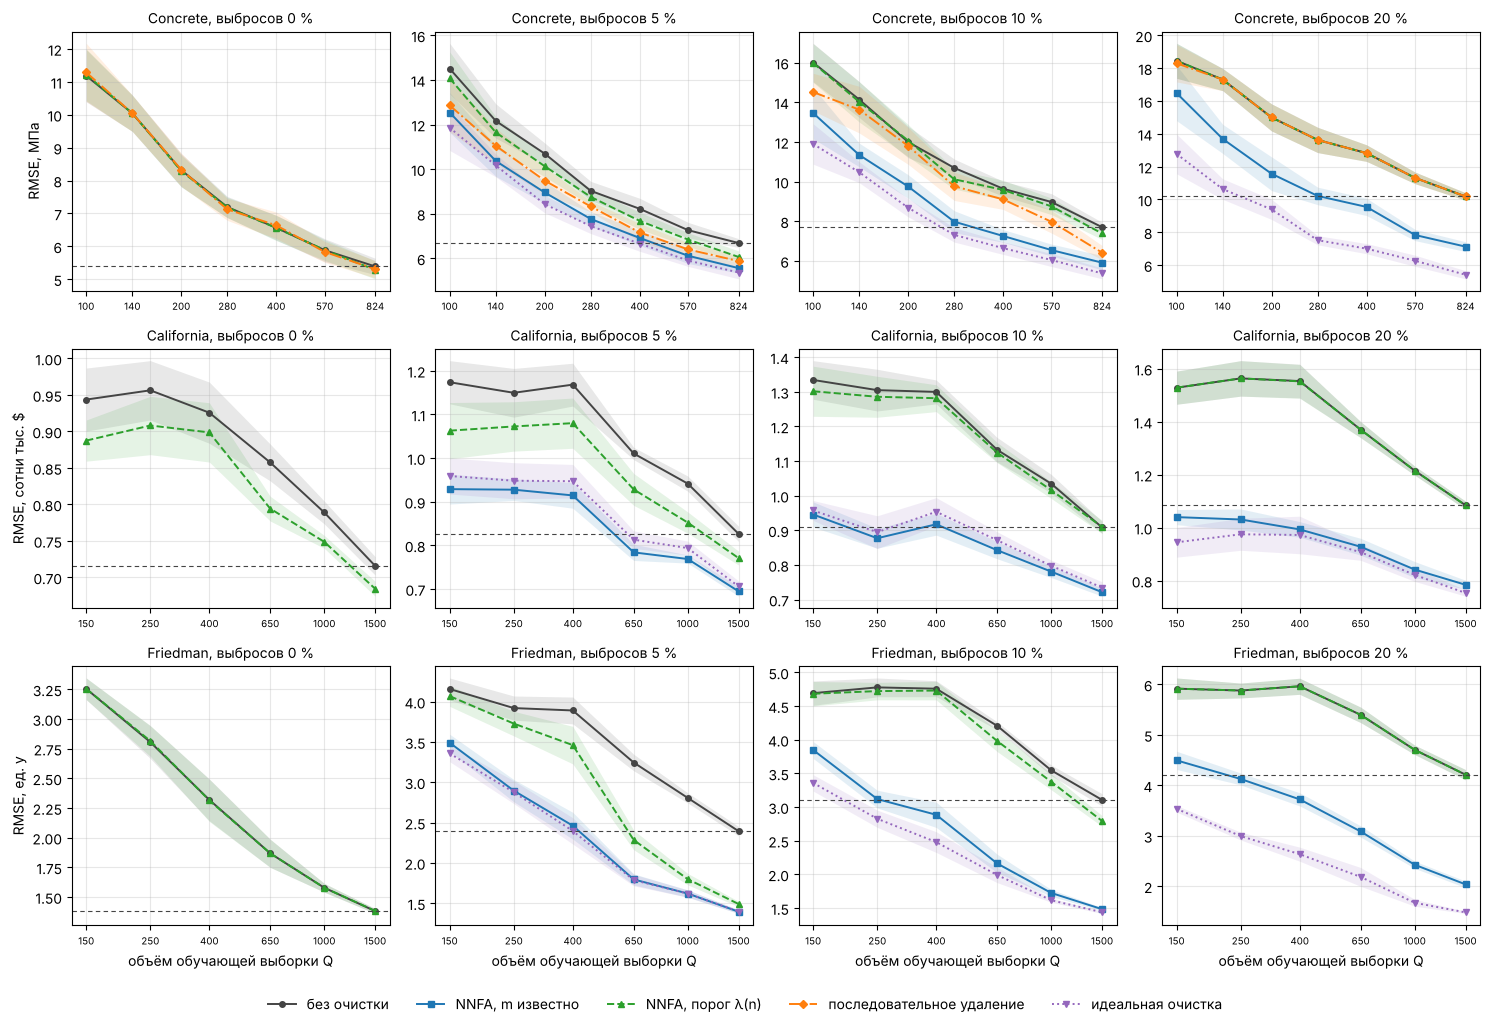

In [6]:
ORDER = ["без очистки", "NNFA, m известно", "NNFA, порог λ(n)", "последовательное удаление", "идеальная очистка"]
STYLE = {"без очистки": ("#444444", "-", "o"), "NNFA, m известно": ("#1f77b4", "-", "s"),
         "NNFA, порог λ(n)": ("#2ca02c", "--", "^"), "последовательное удаление": ("#ff7f0e", "-.", "D"),
         "идеальная очистка": ("#9467bd", ":", "v")}
UNITS = {"Concrete": "МПа", "California": "сотни тыс. $", "Friedman": "ед. y"}
DATASETS = list(SIZES)
mean = ex.groupby(["dataset", "contamination", "strategy", "Q"]).rmse.agg(["mean", "std", "count"])
mean["h"] = 1.96 * mean["std"] / np.sqrt(mean["count"])

fig, axes = plt.subplots(len(DATASETS), len(CONTAMINATIONS), figsize=(15, 3.4 * len(DATASETS)), squeeze=False)
for i, ds in enumerate(DATASETS):
    for j, c in enumerate(CONTAMINATIONS):
        ax = axes[i, j]
        for st in ORDER:
            if (ds, c, st) not in mean.index.droplevel(3):
                continue
            d = mean.loc[(ds, c, st)]
            col, ls, mk = STYLE[st]
            ax.plot(d.index, d["mean"], color=col, ls=ls, marker=mk, ms=4, lw=1.4, label=st)
            ax.fill_between(d.index, d["mean"] - d["h"], d["mean"] + d["h"], color=col, alpha=0.12, lw=0)
        ax.axhline(mean.loc[(ds, c, "без очистки")]["mean"].iloc[-1], color="#444444", lw=0.8, ls=(0, (4, 3)))
        ax.set_xscale("log"); ax.set_xticks(SIZES[ds]); ax.set_xticklabels(SIZES[ds], fontsize=7)
        ax.minorticks_off(); ax.grid(alpha=0.3)
        ax.set_title(f"{ds}, выбросов {int(c * 100)} %", fontsize=10)
        if j == 0:
            ax.set_ylabel(f"RMSE, {UNITS[ds]}")
        if i == len(DATASETS) - 1:
            ax.set_xlabel("объём обучающей выборки Q")
h, l = axes[0, -1].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG / "rmse_ot_obyoma.png", dpi=150, bbox_inches="tight")
plt.show()

**Что видно на рисунке.**

* Без выбросов (левый столбец) очистка ничего не меняет: кривые совпадают в пределах разброса. Исключение
  составляет California, где порог λ(*n*) удаляет около 1 % наблюдений и ошибка немного снижается (0,684 против
  0,716 при *Q* = 1500). Это собственные аномалии набора, а не внесённые выбросы.
* С выбросами кривая без очистки идёт заметно выше, и разрыв растёт с долей выбросов. При наибольшем объёме
  RMSE без очистки на Concrete равен 6,69, 7,70 и 10,18 МПа при 5, 10 и 20 % выбросов против 5,39 МПа на
  чистых данных. На California это 0,83, 0,91 и 1,08 против 0,72, на функции Фридмана 2,39, 3,11 и 4,21
  против 1,38.
* NNFA при известном *m* почти полностью убирает этот разрыв. При наибольшем объёме: Concrete 5,56, 5,91 и
  7,12 МПа, California 0,69, 0,72 и 0,78, Фридман 1,40, 1,48 и 2,04. Кривая NNFA лежит рядом с кривой идеальной
  очистки. Заметно отстаёт она только при 20 % выбросов на Concrete и функции Фридмана: там NNFA удаляет
  четверть "не тех" наблюдений (таблица в п. 5.5).
* На California при 5 и 10 % NNFA даже немного точнее идеальной очистки. Вместе с внесёнными выбросами он
  удаляет и часть собственных аномалий набора, а идеальная очистка их оставляет.
* У California и функции Фридмана при 10 и 20 % выбросов кривая без очистки на малых объёмах почти горизонтальна:
  при *Q* = 150…400 модель почти ничему не учится (на функции Фридмана RMSE 4,7 при СКО *y* 4,9). После очистки
  модель обучается уже при *Q* = 150. Поэтому выигрыш в объёме на этих наборах получается особенно большим.
* Варианты без знания *m* (порог λ(*n*) и последовательное удаление) помогают при 5 % выбросов, слабо помогают при
  10 % и совсем не работают при 20 %: их кривые совпадают с кривой без очистки.

### 5.2. Кратность снижения объёма при полном объёме выборки

Для каждой стратегии: цель (RMSE без очистки при *Q*<sub>max</sub>), объём *q*<sub>min</sub>, при котором стратегия
достигает цели, и кратность снижения. В скобках 95 %-й бутстреп-интервал (1000 выборок повторов с
возвращением). "Не меньше" означает, что очищенная выборка точнее цели уже при наименьшем объёме сетки и
точное значение не определяется. "Цель не достигнута" означает, что стратегия не догоняет вариант без
очистки даже при *Q*<sub>max</sub>.

Объём, нужный без очистки, тоже определяется по кривой, а не принимается равным *Q*<sub>max</sub>. На
участках, где средняя кривая без очистки не убывает (такие есть у California и Фридмана при малых *Q*),
это даёт кратность 1 для стратегий, которые почти ничего не удаляют, а не ложный выигрыш.

In [7]:
def q_needed(curve, target):
    """Наименьший Q, при котором средний RMSE не выше target (интерполяция по log Q).
    Возвращает (Q, точно) — точно=False, если цель достигнута уже в первом узле сетки."""
    curve = curve.dropna()
    q, r = curve.index.to_numpy(float), curve.to_numpy()
    ok = np.flatnonzero(r <= target)
    if not len(ok):
        return np.nan, True
    j = ok[0]
    if j == 0:
        return q[0], False
    w = (r[j - 1] - target) / (r[j - 1] - r[j])
    return float(np.exp(np.log(q[j - 1]) + w * (np.log(q[j]) - np.log(q[j - 1])))), True


def gain(dirty, clean, target):
    # Во сколько раз меньше данных нужно очищенной выборке для точности target.
    # Возвращает (кратность, нижняя_граница). Объём без очистки тоже берётся по кривой,
    # поэтому при одинаковых кривых кратность равна 1 даже на немонотонном участке.
    qd, ed = q_needed(dirty, target)
    qc, ec = q_needed(clean, target)
    if qc != qc or (not ed and not ec):
        return np.nan, False
    return qd / qc, not ec


piv = ex.pivot_table(index=["dataset", "contamination", "strategy", "run"], columns="Q", values="rmse")
boot_rng = np.random.default_rng(0)
B = 200 if SMOKE else 1000
rows = []
for ds in DATASETS:
    qmax = max(SIZES[ds])
    for c in CONTAMINATIONS:
        sub = piv.loc[(ds, c)]
        strats = [s for s in ORDER if s in sub.index.get_level_values(0) and s != "без очистки"]
        mean_c = {s: sub.loc[s].mean().dropna() for s in strats + ["без очистки"]}
        target = mean_c["без очистки"][qmax]
        runs = sub.loc["без очистки"].index.to_numpy()
        boots = {s: [] for s in strats}
        for _ in range(B):
            pick = boot_rng.choice(runs, size=len(runs), replace=True)
            db = sub.loc["без очистки"].loc[pick].mean().dropna()
            for s in strats:
                boots[s].append(gain(db, sub.loc[s].loc[pick].mean().dropna(), db[qmax])[0])
        for s in strats:
            g, lower = gain(mean_c["без очистки"], mean_c[s], target)
            qn, _ = q_needed(mean_c[s], target)
            b = np.array(boots[s])
            rows.append(dict(набор=ds, выбросов=f"{int(c * 100)} %", стратегия=s, цель=round(target, 3),
                             q_min=round(qn) if qn == qn else np.nan, кратность=round(g, 2),
                             ди_низ=round(np.nanpercentile(b, 2.5), 2), ди_верх=round(np.nanpercentile(b, 97.5), 2),
                             цель_достигнута=round(np.isfinite(b).mean(), 3), нижняя_граница=lower))
ratio = pd.DataFrame(rows)
ratio.to_csv(RES / "kratnost_qmax.csv", index=False)
def fmt(r):
    if r.кратность != r.кратность:
        return "цель не достигнута"
    v = f"{r.кратность:.2f}" + (" (не меньше)" if r.нижняя_граница else "")
    return v + f" [{r.ди_низ:.2f}; {r.ди_верх:.2f}]"


ratio["кратность [95 % ДИ]"] = ratio.apply(fmt, axis=1)
(ratio.pivot_table(index=["набор", "выбросов"], columns="стратегия", values="кратность [95 % ДИ]", aggfunc="first")
      .reindex(columns=[s for s in ORDER[1:] if s in set(ratio.стратегия)])
      .reindex([(d, f"{int(c * 100)} %") for d in DATASETS for c in CONTAMINATIONS]).fillna("—"))

стратегия                            NNFA, m известно    NNFA, порог λ(n) последовательное удаление                 идеальная очистка
набор      выбросов                                                                                                                  
Concrete   0 %                                      —   1.07 [1.01; 1.13]         1.06 [1.02; 1.10]                                 —
           5 %                      1.86 [1.65; 2.10]   1.34 [1.24; 1.50]         1.65 [1.44; 1.93]                 2.08 [1.88; 2.32]
           10 %                     2.57 [2.20; 3.07]   1.09 [1.05; 1.15]         1.36 [1.24; 1.56]                 3.24 [2.90; 3.63]
           20 %                     2.89 [2.13; 3.33]   1.00 [1.00; 1.00]         1.00 [1.00; 1.00]                 5.17 [4.45; 6.00]
California 0 %                                      —   1.22 [1.13; 1.31]                         —                                 —
           5 %                      2.70 [2.45; 2.98]   1.32 [1.21; 1.49]                         —                 2.42 [1.99; 2.67]
           10 %                     7.57 [3.72; 9.77]  цель не достигнута                         —                 6.71 [2.49; 8.86]
           20 %      10.00 (не меньше) [10.00; 10.00]   1.00 [1.00; 1.00]                         —  10.00 (не меньше) [10.00; 10.00]
Friedman   0 %                                      —  цель не достигнута                         —                                 —
           5 %                      3.57 [3.31; 3.99]   2.41 [2.28; 2.51]                         —                 3.74 [3.43; 4.19]
           10 %                     5.85 [4.38; 6.61]   1.24 [1.17; 1.32]                         —                 7.85 [7.19; 8.58]
           20 %                     6.75 [5.60; 8.27]   1.00 [1.00; 1.00]                         —  10.00 (не меньше) [10.00; 10.00]

**Итог по мере 1.**

* При известном числе выбросов очистка NNFA снижает нужный объём выборки на всех трёх наборах и при всех долях
  выбросов. На Concrete в 1,9, 2,6 и 2,9 раза при 5, 10 и 20 %. На функции Фридмана в 3,6, 5,9 и 6,8 раза. На
  California в 2,7 раза при 5 %, примерно в 7,6 раза при 10 % и не меньше чем в 10 раз при 20 %, где очищенная
  выборка из 150 наблюдений уже точнее неочищенной из 1500. Нижние границы 95 %-х интервалов больше 1 во всех
  случаях.
* Чем больше выбросов, тем больше выигрыш. Величина выигрыша зависит и от набора: она тем больше, чем медленнее
  убывает кривая без очистки. Поэтому на California при 10 % интервал широкий (от 3,7 до 9,8 раза): точка
  пересечения с целью попадает на пологий участок, где небольшой сдвиг кривой сильно меняет объём.
* Без знания числа выбросов выигрыш скромнее: порог λ(*n*) даёт от 1,3 до 2,4 раза при 5 %, от 1,1 до 1,2 раза
  при 10 % (на California при 10 % цель не достигается) и ничего при 20 %. Последовательное удаление на Concrete даёт 1,65 раза при 5 % и 1,36 раза при 10 %.
* На чистых данных очистка не ухудшает результат: кратность 1,06–1,07 на Concrete, 1,22 на California за счёт
  собственных аномалий набора. На функции Фридмана порог почти ничего не удаляет, и кривая совпадает с кривой
  без очистки (формально цель не достигается из-за разницы в третьем знаке).

**Сравнение с предварительным экспериментом.** В нём (таблица `Код_и_результаты/results/exp4_sample_size.csv`) для Concrete получено 2,4 раза при 5 % и 2,5 раза при 10 %, здесь
1,9 и 2,6. При 10 % оценки совпадают, при 5 % различие больше доверительных интервалов. Интервалы учитывают
только разброс между повторами, а оценка зависит ещё и от сетки объёмов и выбора разбиений. Поэтому для
Concrete правильнее говорить о снижении "примерно в 2–3 раза", чем о конкретном числе.

### 5.3. Выигрыш по всему диапазону объёмов

Для каждого объёма *Q*<sub>0</sub> сетки (кроме наименьшего) цель задаётся как RMSE без очистки при *Q*<sub>0</sub>,
и находится объём, при котором очищенная выборка даёт ту же точность. На рисунке показано отношение объёма,
нужного без очистки, к объёму, нужному после очистки. Значение 1 означает отсутствие выигрыша, 2 означает, что очищенной выборке нужно вдвое меньше
данных. Незакрашенные маркеры отмечают нижние границы: очищенная выборка точнее цели уже при наименьшем
объёме сетки.

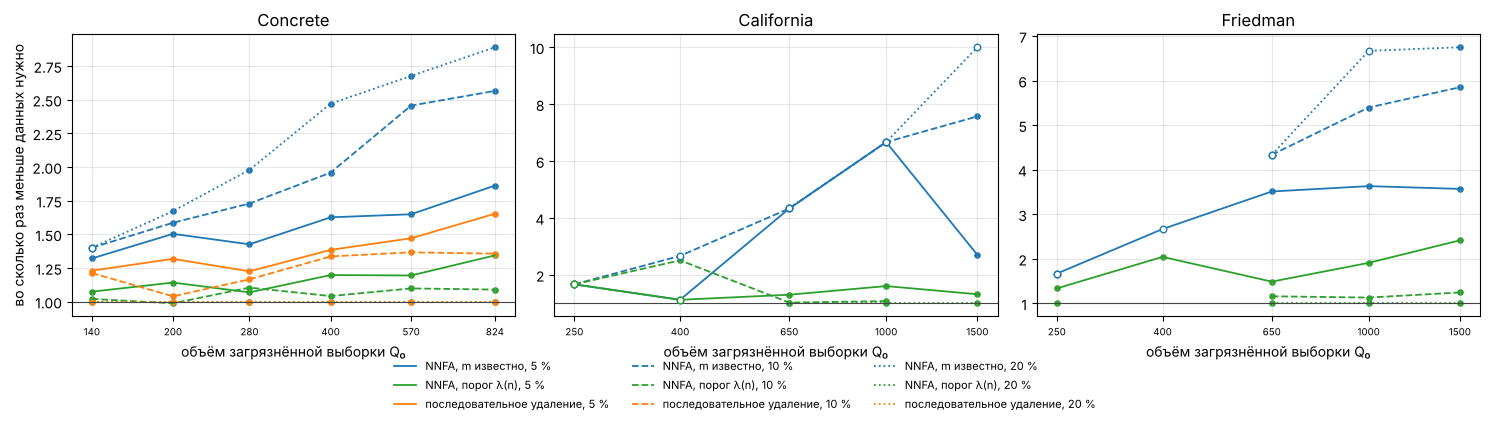

выбросов                                 10 %                                                                              20 %                                                                       \
Q0                                       140      200       250   280       400   570       650   824       1000  1500     140      200       250      280      400   570       650   824       1000   
dataset    strategy                                                                                                                                                                                    
California NNFA, m известно               NaN      NaN  1.67 (≥)   NaN  2.67 (≥)   NaN  4.33 (≥)   NaN  6.67 (≥)  7.57      NaN      NaN       NaN      NaN      NaN   NaN  4.33 (≥)   NaN  6.67 (≥)   
           NNFA, порог λ(n)               NaN      NaN  1.67 (≥)   NaN      2.51   NaN      1.03   NaN      1.08   NaN      NaN      NaN       NaN      NaN      NaN   NaN       1.0   NaN       1.0   
           идеальная очистка              NaN      NaN  1.67 (≥)   NaN  2.67 (≥)   NaN  4.33 (≥)   NaN  6.67 (≥)  6.71      NaN      NaN       NaN      NaN      NaN   NaN  4.33 (≥)   NaN  6.67 (≥)   
Concrete   NNFA, m известно           1.4 (≥)     1.59       NaN  1.73      1.96  2.46       NaN  2.57       NaN   NaN  1.4 (≥)     1.67       NaN     1.98     2.47  2.68       NaN  2.89       NaN   
           NNFA, порог λ(n)              1.02     0.99       NaN   1.1      1.04   1.1       NaN  1.09       NaN   NaN      1.0      1.0       NaN      1.0      1.0   1.0       NaN   1.0       NaN   
           идеальная очистка          1.4 (≥)  2.0 (≥)       NaN  2.11      2.42  3.02       NaN  3.24       NaN   NaN  1.4 (≥)  2.0 (≥)       NaN  2.8 (≥)  4.0 (≥)  4.53       NaN  5.17       NaN   
           последовательное удаление     1.21     1.04       NaN  1.17      1.34  1.37       NaN  1.36       NaN   NaN      1.0      1.0       NaN      1.0      1.0   1.0       NaN   1.0       NaN   
Friedman   NNFA, m известно               NaN      NaN       NaN   NaN       NaN   NaN  4.33 (≥)   NaN       5.4  5.85      NaN      NaN  1.67 (≥)      NaN      NaN   NaN  4.33 (≥)   NaN  6.67 (≥)   
           NNFA, порог λ(n)               NaN      NaN       NaN   NaN       NaN   NaN      1.16   NaN      1.13  1.24      NaN      NaN       1.0      NaN      NaN   NaN       1.0   NaN       1.0   
           идеальная очистка              NaN      NaN       NaN   NaN       NaN   NaN  4.33 (≥)   NaN  6.67 (≥)  7.85      NaN      NaN  1.67 (≥)      NaN      NaN   NaN  4.33 (≥)   NaN  6.67 (≥)   

выбросов                                            5 %                                                                        
Q0                                        1500     140   200       250   280       400   570       650   824       1000  1500  
dataset    strategy                                                                                                            
California NNFA, m известно           10.0 (≥)      NaN   NaN  1.67 (≥)   NaN  1.12 (≥)   NaN  4.33 (≥)   NaN  6.67 (≥)   2.7  
           NNFA, порог λ(n)                1.0      NaN   NaN  1.67 (≥)   NaN  1.12 (≥)   NaN       1.3   NaN      1.61  1.32  
           идеальная очистка          10.0 (≥)      NaN   NaN  1.67 (≥)   NaN  1.12 (≥)   NaN  4.33 (≥)   NaN      2.45  2.42  
Concrete   NNFA, m известно                NaN     1.32   1.5       NaN  1.43      1.63  1.65       NaN  1.86       NaN   NaN  
           NNFA, порог λ(n)                NaN     1.07  1.14       NaN  1.07       1.2  1.19       NaN  1.34       NaN   NaN  
           идеальная очистка               NaN  1.4 (≥)  1.59       NaN  1.58      1.86  1.87       NaN  2.08       NaN   NaN  
           последовательное удаление       NaN     1.23  1.32       NaN  1.22      1.38  1.47       NaN  1.65       NaN   NaN  
Friedman   NNFA, m известно               6.75      NaN   NaN  1.67 (≥)   NaN  2.67 (≥)   NaN      3.51   NaN      3.63

In [8]:
rows = []
for ds in DATASETS:
    for c in CONTAMINATIONS:
        sub = mean.loc[(ds, c)]["mean"]
        base = sub.loc["без очистки"]
        for s in ORDER[1:]:
            if s not in sub.index.get_level_values(0):
                continue
            for q0 in SIZES[ds][1:]:
                g, lower = gain(base, sub.loc[s], base[q0])
                rows.append(dict(dataset=ds, contamination=c, strategy=s, Q0=q0,
                                 ratio=g, exact=not lower))
eq = pd.DataFrame(rows)
eq.to_csv(RES / "kratnost_po_diapazonu.csv", index=False)

fig, axes = plt.subplots(1, len(DATASETS), figsize=(15, 3.8), squeeze=False)
for ax, ds in zip(axes[0], DATASETS):
    for c, ls in zip([c for c in CONTAMINATIONS if c > 0], ["-", "--", ":"]):
        for s in ["NNFA, m известно", "NNFA, порог λ(n)", "последовательное удаление"]:
            d = eq[(eq.dataset == ds) & (eq.contamination == c) & (eq.strategy == s)]
            if d.empty:
                continue
            col = STYLE[s][0]
            ax.plot(d.Q0, d.ratio, color=col, ls=ls, lw=1.3, label=f"{s}, {int(c * 100)} %")
            ax.scatter(d.Q0[d.exact], d.ratio[d.exact], color=col, s=14)
            ax.scatter(d.Q0[~d.exact], d.ratio[~d.exact], facecolors="white", edgecolors=col, s=22, zorder=3)
    ax.axhline(1, color="#444444", lw=0.8)
    ax.set_xscale("log"); ax.set_xticks(SIZES[ds][1:]); ax.set_xticklabels(SIZES[ds][1:], fontsize=7)
    ax.minorticks_off(); ax.grid(alpha=0.3)
    ax.set_title(ds); ax.set_xlabel("объём загрязнённой выборки Q₀")
axes[0, 0].set_ylabel("во сколько раз меньше данных нужно")
h, l = [], []
for ax in axes[0]:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.12))
fig.tight_layout()
fig.savefig(FIG / "kratnost_po_diapazonu.png", dpi=150, bbox_inches="tight")
plt.show()

(eq[eq.contamination > 0].assign(выбросов=lambda d: (d.contamination * 100).astype(int).astype(str) + " %",
                                 r=lambda d: d.ratio.round(2).astype(str) + np.where(d.exact, "", " (≥)"))
   .pivot_table(index=["dataset", "strategy"], columns=["выбросов", "Q0"], values="r", aggfunc="first"))

**Итог по мере 2.** Выигрыш есть не только при полном объёме выборки. На Concrete при известном *m* кратность
растёт с объёмом: при 5 % выбросов от 1,3 при малых объёмах до 1,9 при *Q* = 824, при 10 % от 1,6 до 2,6, при 20 %
от 1,7 до 2,9. На функции Фридмана при 5 % она держится на уровне 3,5–3,6 во всём диапазоне от 650 до 1500.
На California и функции Фридмана при 10 и 20 % большинство точек являются нижними границами: очищенная
выборка из 150 наблюдений уже точнее неочищенной, поэтому сетка объёмов не позволяет измерить выигрыш точнее.

При малых объёмах на California кривая без очистки не убывает, и там кратность определяется плохо. Поэтому
главные выводы опираются на меру 1 и на участок больших объёмов.

### 5.4. Значимость

Для каждой тройки (набор, доля выбросов, стратегия) берутся все пары (*Q*, повтор): RMSE стратегии и RMSE без
очистки, полученные на одних и тех же данных. Указываются средняя разность (отрицательная означает, что
очистка лучше), доля пар, где очистка лучше, и *p* парного критерия Уилкоксона с поправкой Холма по всем
сравнениям таблицы.

In [9]:
w = ex.pivot_table(index=["dataset", "contamination", "Q", "run"], columns="strategy", values="rmse")
rows = []
for (ds, c), g in w.groupby(level=[0, 1]):
    for s in ORDER[1:]:
        if s not in g or g[s].isna().all():
            continue
        d = (g[s] - g["без очистки"]).dropna()
        p = wilcoxon(d).pvalue if (d != 0).any() else 1.0
        rows.append(dict(набор=ds, выбросов=f"{int(c * 100)} %", стратегия=s, пар=len(d),
                         разность=round(d.mean(), 3), доля_лучше=round((d < 0).mean(), 3), p=p))
tests = pd.DataFrame(rows)
order = np.argsort(tests.p.to_numpy()); adj = np.empty(len(tests)); run_max = 0.0
for rank, i in enumerate(order):                       # поправка Холма
    run_max = max(run_max, (len(tests) - rank) * tests.p.iloc[i]); adj[i] = min(1.0, run_max)
tests["p_Холм"] = adj
tests.to_csv(RES / "znachimost.csv", index=False)
tests.assign(p=tests.p.map("{:.1e}".format), p_Холм=tests.p_Холм.map("{:.1e}".format))

,набор,выбросов,стратегия,пар,разность,доля_лучше,p,p_Холм
0,California,0 %,"NNFA, порог λ(n)",72,-0.044,0.833,2.4e-11,3.4e-10
1,California,5 %,"NNFA, m известно",72,-0.209,1.000,1.7e-13,4.5e-12
2,California,5 %,"NNFA, порог λ(n)",72,-0.084,0.917,3.0e-12,4.5e-11
3,California,5 %,идеальная очистка,72,-0.184,1.000,1.7e-13,4.5e-12
4,California,10 %,"NNFA, m известно",72,-0.322,1.000,1.7e-13,4.5e-12
5,California,10 %,"NNFA, порог λ(n)",72,-0.016,0.500,8.2e-03,6.6e-02
6,California,10 %,идеальная очистка,72,-0.301,1.000,1.7e-13,4.5e-12
7,California,20 %,"NNFA, m известно",72,-0.449,1.000,1.7e-13,4.5e-12
8,California,20 %,"NNFA, порог λ(n)",72,-0.000,0.014,3.2e-01,1.0e+00
9,California,20 %,идеальная очистка,72,-0.490,1.000,1.7e-13,4.5e-12


**Итог по значимости.** NNFA при известном *m* и идеальная очистка лучше варианта без очистки в 95–100 % пар
на всех наборах и при всех долях выбросов (*p* с поправкой Холма меньше 10<sup>−10</sup>). Порог λ(*n*) значимо лучше
при 5 % выбросов на всех наборах и при 10 % на функции Фридмана; при 10 % на Concrete и California различие
не значимо после поправки, при 20 % его нет. Последовательное удаление на Concrete значимо лучше при 5 и 10 %.
На чистых данных значимое отличие только одно: порог на California, и оно в пользу очистки.

### 5.5. Что удаляют варианты без знания числа выбросов

Средние по всем объёмам *Q*: сколько наблюдений удалено относительно числа внесённых выбросов, доля настоящих
выбросов среди удалённых (точность) и доля найденных выбросов (полнота). При 0 % выбросов любое удаление
является ложным срабатыванием, поэтому для контроля приведено среднее число удалённых наблюдений.

In [10]:
det = ex[ex.strategy.isin(["NNFA, m известно", "NNFA, порог λ(n)", "последовательное удаление"])].copy()
det["удалено_к_m"] = det.n_removed / det.m.where(det.m > 0)
det["удалено_доля_Q"] = det.n_removed / det.Q
(det.groupby(["dataset", "contamination", "strategy"])
    [["n_removed", "удалено_доля_Q", "удалено_к_m", "precision", "recall"]].mean().round(3))

n_removed  удалено_доля_Q  удалено_к_m  precision  recall
dataset    contamination strategy                                                                            
California 0.00          NNFA, порог λ(n)               6.931           0.011          NaN      0.000     NaN
           0.05          NNFA, m известно              32.833           0.050        1.000      0.683   0.683
                         NNFA, порог λ(n)              11.917           0.017        0.332      0.730   0.243
           0.10          NNFA, m известно              65.833           0.100        1.000      0.727   0.727
                         NNFA, порог λ(n)               2.444           0.004        0.038      0.583   0.025
           0.20          NNFA, m известно             131.667           0.200        1.000      0.720   0.720
                         NNFA, порог λ(n)               0.014           0.000        0.000      0.000   0.000
Concrete   0.00          NNFA, порог λ(n)               0.286           0.001          NaN      0.000     NaN
                         последовательное удаление      0.476           0.002          NaN      0.000     NaN
           0.05          NNFA, m известно              17.857           0.050        1.000      0.815   0.815
                         NNFA, порог λ(n)               8.083           0.018        0.355      0.995   0.353
                         последовательное удаление     13.083           0.033        0.669      0.955   0.635
           0.10          NNFA, m известно              35.857           0.100        1.000      0.821   0.821
                         NNFA, порог λ(n)               4.643           0.010        0.103      1.000   0.103
                         последовательное удаление     15.071           0.033        0.327      0.988   0.322
           0.20          NNFA, m известно              71.857           0.200        1.000      0.752   0.752
                         NNFA, порог λ(n)               0.000           0.000        0.000        NaN   0.000
                         последовательное удаление      0.024           0.000        0.001      1.000   0.001
Friedman   0.00          NNFA, порог λ(n)               0.042           0.000          NaN      0.000     NaN
           0.05          NNFA, m известно              32.833           0.050        1.000      0.925   0.925
                         NNFA, порог λ(n)              23.306           0.024        0.477      1.000   0.477
           0.10          NNFA, m известно              65.833           0.100        1.000      0.866   0.866
                         NNFA, порог λ(n)               8.847           0.008        0.077      1.000   0.077
           0.20          NNFA, m известно             131.667           0.200        1.000      0.774   0.774
                         NNFA, порог λ(n)               0.000           0.000        0.000        NaN   0.000

**Почему варианты без знания *m* слабее.** Они удаляют мало, и в основном настоящие выбросы. Порог λ(*n*) при 5 %
выбросов находит 35 % выбросов на Concrete, 24 % на California и 48 % на функции Фридмана, при 10 % от 3 до 10 %,
при 20 % ни одного. Точность удаления при этом от 0,58 до 1,00. Последовательное удаление на Concrete находит 64 %
выбросов при 5 % и 32 % при 10 %. Причина в самом критерии остановки: многочисленные выбросы
увеличивают медиану невязок, статистика *z* опускается ниже порога, и удаление прекращается. При 20 % выбросов
статистика не превышает порог уже на первом шаге.

Для сравнения, NNFA при известном *m* удаляет ровно *m* наблюдений, и настоящих выбросов среди них 75–82 % на
Concrete, 68–73 % на California и 77–93 % на функции Фридмана. На чистых данных порог λ(*n*) удаляет в среднем
0,3 наблюдения на Concrete, 0,04 на функции Фридмана и около 7 (1 %) на California.

## 6. Выводы и ограничения

1. **Утверждение авторов подтверждается на трёх наборах данных.** Если число выбросов известно, очистка
   методом NNFA позволяет получить ту же точность нейросетевой модели на выборке меньшего объёма: на Concrete
   примерно в 2–3 раза, на функции Фридмана в 3,5–7 раз, на California от 2,7 раза при 5 % выбросов до 10 раз и
   более при 20 %. Выигрыш значим во всех случаях и близок к выигрышу от идеальной очистки.
2. **Выигрыш растёт с долей выбросов** и сильнее всего проявляется там, где выбросы почти не дают модели
   обучаться на малой выборке (California и функция Фридмана при 10–20 %).
3. **Очистка не вредит чистым данным.** Без внесённых выбросов варианты без знания *m* почти ничего не удаляют,
   а на California удаляют собственные аномалии набора и немного повышают точность.
4. **Без знания числа выбросов вывод выполняется только при умеренном загрязнении.** Порог λ(*n*) и
   последовательное удаление дают выигрыш в 1,3–2,4 раза при 5 % выбросов, небольшой при 10 % и никакого при 20 %,
   потому что останавливаются слишком рано. Для практического применения нужен способ оценивать число
   выбросов, устойчивый к сильному загрязнению.

**Ограничения.**

* Выбросы внесены искусственно, только в *y*, одной мощности 2σ. Другие типы аномалий не проверялись.
* Итоговая модель одна: персептрон (32, 16). С другой моделью величина выигрыша может быть другой.
* Кратность определяется по сетке из 6–7 объёмов с интерполяцией, поэтому она приблизительна, а при очень
  большом выигрыше известна только её нижняя граница. Доверительные интервалы учитывают разброс между повторами,
  но не выбор сетки и разбиений.
* Последовательное удаление проверено только на Concrete из-за времени расчёта.
* California использован с логарифмированием и обрезкой признаков с длинными хвостами (п. 2).